# Natural frequency analysis of a plate

Simply supported plates of `Quad4` elements, whose lowest natural frequencies
are compared with the exact ones of Leissa (1969): first with the consistent
mass matrix, with and without the equilibration of the diagonal done by
`pyfe3d.solver.natural_frequency`, then with the three mass matrices of
`Quad4`. The analysis is described in
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst) and the
mass matrices in [Mass matrices of the shells](../shell_mass.rst); the full
references are at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from numpy import isclose
from scipy.sparse import coo_matrix

from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import natural_frequency

## The reference values

The free vibrations $\boldsymbol{u} \sin(\omega_n t)$ give the eigenvalue
problem $(\boldsymbol{K}_{C0} - \omega_n^2 \boldsymbol{M}) \boldsymbol{u} =
\boldsymbol{0}$. For the Kirchhoff plate with all edges simply supported,
Leissa (1969, Sec. 4.1, p. 44, Eq. (4.20)) gives the exact frequencies

$$
\omega_{mn} = \sqrt{\frac{D}{\rho h}} \left[\left(\frac{m \pi}{a}\right)^2
+ \left(\frac{n \pi}{b}\right)^2\right], \qquad
D = \frac{E h^3}{12 (1 - \nu^2)}
$$

with $\rho h$ the mass per unit area (Leissa's $\rho$); the lowest is $m = n =
1$:

In [2]:
def leissa(a, b, h, E, nu, rho, m=1, n=1):
    D = E*h**3/(12*(1 - nu**2))
    return np.sqrt(D/(rho*h))*((m*np.pi/a)**2 + (n*np.pi/b)**2)

## The model

The function below builds a rectangular plate of `nx` by `ny` nodes and
assembles $\boldsymbol{K}_{C0}$ with `update_KC0` and $\boldsymbol{M}$ with
`update_M`, whose `mtype` selects the consistent (0), lumped (1) or
reduced-integration (2) mass matrix. All translations of the edge nodes are
held. With `hard=True` the rotation about the axis of each edge is also
held, the hard simple support:

In [3]:
def plate(a, b, h, E, nu, rho, nx, ny, mtype=0, hard=False):
    prop = isotropic_plate(thickness=h, E=E, nu=nu, rho=rho)
    data = Quad4Data()
    probe = Quad4Probe()
    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(),
                         np.zeros(nx*ny))).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    ncoords_flatten = ncoords.flatten()
    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*nx*ny
    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    Mr = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mc = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mv = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
        quad = Quad4(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        quad.init_k_M = k*data.M_SPARSE_SIZE
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quad.update_M(Mr, Mc, Mv, prop, mtype=mtype)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    M = coo_matrix((Mv, (Mr, Mc)), shape=(N, N)).tocsc()
    bk = np.zeros(N, dtype=bool)
    edge = isclose(x, 0.) | isclose(x, a) | isclose(y, 0.) | isclose(y, b)
    bk[0::DOF] = edge
    bk[1::DOF] = edge
    bk[2::DOF] = edge
    if hard:
        bk[3::DOF] = isclose(x, 0.) | isclose(x, a)
        bk[4::DOF] = isclose(y, 0.) | isclose(y, b)
    bu = ~bk
    return KC0[bu, :][:, bu], M[bu, :][:, bu], bu, xmesh, ymesh

## 1. Consistent mass matrix, with and without equilibration

The plate has $a = 2$ m, $b = 0.5$ m, $h = 0.002$ m, $E = 203$ GPa, $\nu =
0.33$ and $\rho = 7830$ kg/m$^3$, meshed with the consistent mass matrix. With
$b/h = 250$ the frequency of the Mindlin plate, with its rotary inertia, is
0.003 % below the Kirchhoff value. `natural_frequency` equilibrates the
diagonal of $\boldsymbol{K}_{C0}$ before calling the eigensolver, unless
`precondition=False`; the frequencies must not depend on it:

In [4]:
a, b, h, E, nu, rho = 2.0, 0.5, 0.002, 203.e9, 0.33, 7830.
w11 = leissa(a, b, h, E, nu, rho)
print('%-9s %14s %14s %11s %22s' % ('elements', 'omega_1 (rad/s)',
      'Leissa', 'rel. diff.', 'without equilibration'))
for nx, ny in [(21, 7), (41, 13), (61, 19), (81, 25)]:
    KC0uu, Muu, bu, xmesh, ymesh = plate(a, b, h, E, nu, rho, nx, ny)
    omegan, eigvecs = natural_frequency(KC0uu, Muu, num_eigvalues=4)
    omegan_raw, _ = natural_frequency(KC0uu, Muu, num_eigvalues=4,
                                      precondition=False)
    print('%-9s %14.4f %14.4f %11.2e %22.4f' % ('%dx%d' % (nx - 1, ny - 1),
          omegan[0], w11, omegan[0]/w11 - 1, omegan_raw[0]))

elements  omega_1 (rad/s)         Leissa  rel. diff.  without equilibration
20x6            134.9134       130.6267    3.28e-02               134.9134


40x12           131.6722       130.6267    8.00e-03               131.6722


60x18           131.0857       130.6267    3.51e-03               131.0857


80x24           130.8809       130.6267    1.95e-03               130.8809


## 2. The three mass matrices

The plate $a = 0.3$ m, $b = 0.5$ m, $h = 0.01$ m, with the same material, and
hard simply supported edges, for which the Navier mode is also exact for the
Mindlin plate: with $a/h = 30$, the rotary inertia and $A_{44} = A_{55} =
(5/6) G h$, its frequency is 0.28 % below the Kirchhoff value, from the
characteristic equation (76) of Wittrick (1987, Sec. 3.2, p. 457), and the
elements converge to that value. With the soft simple support, rotations
free, they would converge to about 1 % below the reference, through the
boundary layer of the Mindlin plate along the edges. Three meshes with each
mass matrix:

In [5]:
a, b, h = 0.3, 0.5, 0.01
w11 = leissa(a, b, h, E, nu, rho)
mtypes = {0: 'consistent', 1: 'lumped', 2: 'reduced'}
print('Leissa, Eq. (4.20): omega_11 = %.4f rad/s' % w11)
print('%-11s %-9s %16s %11s' % ('mass', 'elements', 'omega_1 (rad/s)',
                                'rel. diff.'))
conv = {}
for mtype, label in mtypes.items():
    conv[mtype] = []
    for refinement in [1, 2, 3, 4]:
        nx, ny = 9*refinement, 11*refinement
        KC0uu, Muu, bu, xmesh, ymesh = plate(a, b, h, E, nu, rho, nx, ny,
                                             mtype=mtype, hard=True)
        omegan, eigvecs = natural_frequency(KC0uu, Muu, num_eigvalues=2,
                                            tol=1e-6)
        conv[mtype].append((nx - 1, omegan[0]/w11 - 1))
        print('%-11s %-9s %16.4f %11.2e' % (label, '%dx%d' % (nx - 1, ny - 1),
              omegan[0], omegan[0]/w11 - 1))

Leissa, Eq. (4.20): omega_11 = 2322.2525 rad/s
mass        elements   omega_1 (rad/s)  rel. diff.
consistent  8x10             2353.2540    1.33e-02
consistent  17x21            2323.9452    7.29e-04


consistent  26x32            2319.2090   -1.31e-03


consistent  35x43            2317.6251   -1.99e-03
lumped      8x10             2304.1782   -7.78e-03
lumped      17x21            2313.0231   -3.97e-03


lumped      26x32            2314.5293   -3.33e-03


lumped      35x43            2315.0396   -3.11e-03
reduced     8x10             2378.6043    2.43e-02
reduced     17x21            2329.4459    3.10e-03


reduced     26x32            2321.5561   -3.00e-04


reduced     35x43            2318.9201   -1.43e-03


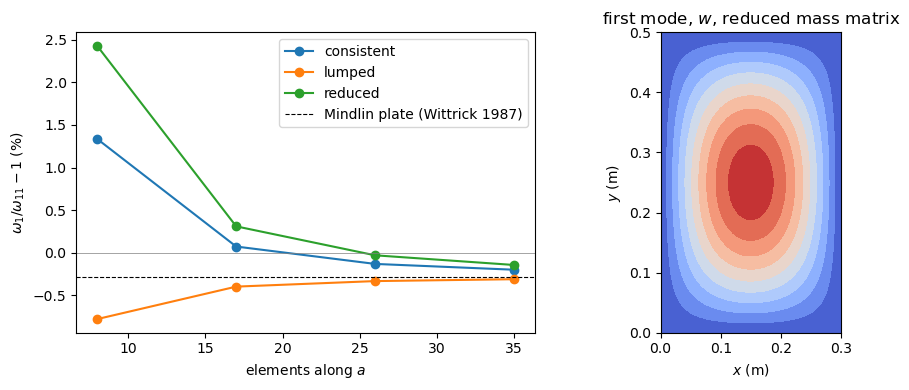

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for mtype, label in mtypes.items():
    ne, err = np.array(conv[mtype]).T
    axs[0].plot(ne, 100*err, 'o-', label=label)
axs[0].axhline(-0.28, color='k', ls='--', lw=0.8,
               label='Mindlin plate (Wittrick 1987)')
axs[0].axhline(0, color='gray', lw=0.5)
axs[0].set_xlabel('elements along $a$')
axs[0].set_ylabel(r'$\omega_1/\omega_{11} - 1$ (%)')
axs[0].legend()

N = DOF*xmesh.size
u = np.zeros(N)
u[bu] = eigvecs[:, 0]
nx, ny = xmesh.shape[1], xmesh.shape[0]
axs[1].set_aspect('equal')
cs = axs[1].contourf(xmesh, ymesh, u[2::DOF].reshape(nx, ny).T, levels=10,
                     cmap='coolwarm')
axs[1].set_title('first mode, $w$, reduced mass matrix')
axs[1].set_xlabel('$x$ (m)')
axs[1].set_ylabel('$y$ (m)')
plt.tight_layout()
plt.show()

On the coarse meshes the consistent and the reduced-integration mass matrices
give frequencies above the reference and the lumped one below it; on the
finer meshes the three approach the Mindlin value, 0.28 % below the Kirchhoff
reference.

## References

- Leissa, A. W., Vibration of Plates, NASA SP-160, 1969.
- Wittrick, W. H., Analytical, three-dimensional elasticity solutions to some
  plate problems, and some observations on Mindlin's plate theory,
  International Journal of Solids and Structures, 23(4), 441-464, 1987.